# 02 - Building a TWPA

This notebook defines a TWPA model and computes its linear response. The built-in cells and the nonlinearity of the `TWPA` class describe kinetic-inductance TWPAs (KI-TWPAs); any other linear cell can be added as a user model (see *Implementing New Models* and notebook 05). Other nonlinearities, such as that of Josephson junctions, are not supported yet.

## Cell parameters

We consider a line with step modulation: a supercell of unloaded and loaded unit cells. For comparison we also define an effective line without modulation, with the mean parameters of the modulated one.

In [1]:
import twpasolver 
print(twpasolver.__path__)

/home/cns20/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


['/home/cns20/twpasolver/src/twpasolver']


In [80]:
import matplotlib.pyplot as plt
import numpy as np

from twpasolver.models import TWPA, LCLfBaseCell, LCLf_shuntLCladder_BaseCell

freqs = np.arange(1e9, 60e9, 2e6)
N_u = 30#60
N_l = 4#6
N_sc = 1000
N = N_sc * (N_u + N_l)

# Cell capacitances, expressed in F
C_u = 26.3E-15#18.81e-15
C_l = 9.9E-15#7.0e-15
C_eff = (N_u * C_u + N_l * C_l) / (N_u + N_l)

# Cell inductances, expressed in H
L_u = 60E-12#45.2e-12
L_l = 60E-12#45.2e-12
L_eff = (N_u * L_u + N_l * L_l) / (N_u + N_l)

# Finger inductances, expressed in H
L_f_u = .360e-9
L_f_l = 0.117e-9
L_f_eff = (N_u * L_f_u + N_l * L_f_l) / (N_u + N_l)

########### 
# The highpass filter design 
shuntR = 15
shuntC = 4.6E-12/shuntR 
shuntL1 = 5.14E-12 *shuntR
shuntL2 = 5.14E-12*shuntR

## Cells and TWPA

`twpasolver.models.TWPA` is a `TwoPortArray` that also holds the parameters of the nonlinear response, which notebook 03 uses for phase matching and gain. `LCLfBaseCell` computes the unit-cell response of Appendix B of [PRX Quantum **2**, 010302 (2021)](https://journals.aps.org/prxquantum/abstract/10.1103/PRXQuantum.2.010302). Dielectric loss enters as the loss tangent `delta` of the capacitor.

In [81]:
unloaded = LCLfBaseCell(C=C_u, L=L_u, Lf=L_f_u, delta=0, N=N_u / 2)
unloaded_minusone = LCLfBaseCell(C=C_u, L=L_u, Lf=L_f_u, delta=0, N=N_u / 2 - 1)
loaded = LCLfBaseCell(C=C_l, L=L_l, Lf=L_f_l, delta=0, N=N_l)
dissipationcell = LCLf_shuntLCladder_BaseCell(C=C_l, L=L_l, Lf=L_f_l, shuntR = shuntR, shuntC = shuntC, shuntL1 = shuntL1, shuntL2 = shuntL2, N=1   )  

twpa = TWPA(cells=[unloaded, loaded, unloaded], N=N_sc)
twpa_loss =  TWPA(cells=[unloaded, loaded, dissipationcell, unloaded_minusone], N=N_sc)
# Effective mean cell and unmodulated TWPA
eff = LCLfBaseCell(C=C_eff, L=L_eff, Lf=L_f_eff, N=N_u + N_l)
twpa_not_loaded = TWPA(cells=[eff], N=N_sc)

twpa_loss.model_dump()
twpa_loss.dump_to_file("TWPA_highpassloss.json")

## Nonlinearity

The nonlinearity is set on the `TWPA`, not on the cells. The kinetic inductance depends on the current $I$ through it as

$$L(I) = L_k \left[1 + (I/I_*)^2 + (I/I_{*2})^4\right],$$

with $I_*$ (`Istar`) and the optional $I_{*2}$ (`Istar2`) in A. With a dc bias $I_{dc}$ (`Idc`) and a small rf current $i$,

$$L = L(I_{dc})\,(1 + \epsilon\, i + \xi\, i^2),$$

where $\epsilon$ (`epsilon`, 1/A) drives three-wave mixing (3WM) and $\xi$ (`xi`, 1/A$^2$) four-wave mixing (4WM). Without $I_{*2}$, $\xi = 1/(I_*^2 + I_{dc}^2)$ and $\epsilon = 2 I_{dc}\,\xi$: an unbiased line mixes four waves only. The series inductance `L` of the cells is the biased one, $L(I_{dc})$, and sets the dispersion as given. `Ip0` is the default pump current, the peak amplitude in A of the pump wave incident at the input; the analysis methods of notebook 03 can override it. We keep the defaults:

In [73]:
print(
    f"Istar = {twpa.Istar * 1e3:.2f} mA, Idc = {twpa.Idc * 1e3:.2f} mA, Ip0 = {twpa.Ip0 * 1e3:.2f} mA"
)
print(f"epsilon = {twpa.epsilon:.3g} 1/A, xi = {twpa.xi:.3g} 1/A^2")

Istar = 6.50 mA, Idc = 1.00 mA, Ip0 = 0.20 mA
epsilon = 46.2 1/A, xi = 2.31e+04 1/A^2


## Linear response

We plot $|S_{21}|$ of both lines: the modulation opens a stopband.

/home/cns20/.local/lib/python3.10/site-packages/skrf/mathFunctions.py:268: RuntimeWarning: divide by zero encountered in log10
  out = 20 * np.log10(z)


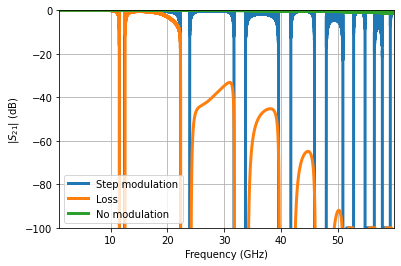

In [82]:
net = twpa.get_network(freqs)
net_unmodulated = twpa_not_loaded.get_network(freqs)
net_loss = twpa_loss.get_network(freqs)
net.s21.plot_s_db(label="Step modulation", lw=3)
net_loss.s21.plot_s_db(label ="Loss", lw = 3)
net_unmodulated.s21.plot_s_db(label="No modulation", lw=3)
plt.ylabel("$|S_{21}|$ (dB)")
plt.ylim([-100, 0])
plt.grid()

The phase of $S_{21}$ per unit cell is the wavenumber $k$, which departs from the linear dispersion $k = 2\pi f\sqrt{L_{eff} C_{eff}}$ of the effective line. We plot the dispersive part $k^* = k - 2\pi f\sqrt{L_{eff} C_{eff}}$, in rad per unit cell: near the stopband the modulation creates a resonance-like profile, which confines phase matching to a controllable frequency range.

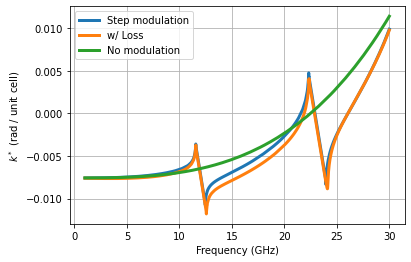

In [78]:
linear_disp = 2 * np.pi * freqs * np.sqrt(C_eff * L_eff)
plt.plot(
    freqs * 1e-9,
    -net.s21.s_rad_unwrap.flatten() / N - linear_disp,
    label="Step modulation",
    lw=3,
)
plt.plot(
    freqs * 1e-9,
    -net_loss.s21.s_rad_unwrap.flatten() / N - linear_disp,
    label="w/ Loss",
    lw=3,
)
plt.plot(
    freqs * 1e-9,
    -net_unmodulated.s21.s_rad_unwrap.flatten() / N - linear_disp,
    label="No modulation",
    lw=3,
)
plt.xlabel("Frequency (GHz)")
plt.ylabel("$k^*$ (rad / unit cell)")
plt.legend()
plt.grid()

## Building cells from basic components

The same TWPA can be composed from basic circuit elements. Here we reproduce the `LCLfBaseCell` model from inductors and capacitors.

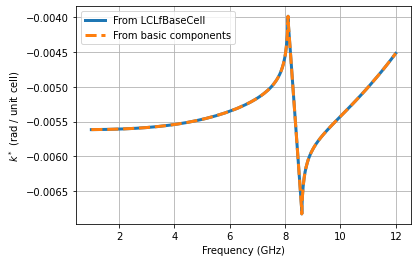

In [6]:
from twpasolver.models import Capacitance, Inductance, compose

L_line_u = Inductance(L=L_u)
fingers_u = compose(
    Capacitance(C=C_u / 2), Inductance(L=L_f_u), N=2, twoport_parallel=True
)
cell_u = compose(L_line_u, fingers_u, N=N_u / 2)

L_line_l = Inductance(L=L_l)
fingers_l = compose(
    Capacitance(C=C_l / 2), Inductance(L=L_f_l), N=2, twoport_parallel=True
)
cell_l = compose(L_line_l, fingers_l, N=N_l)

twpa_from_basic = TWPA(cells=[cell_u, cell_l, cell_u], N=N_sc)

# Plot the nonlinear phase response
plt.plot(
    freqs * 1e-9,
    -net.s21.s_rad_unwrap.flatten() / N - linear_disp,
    label="From LCLfBaseCell",
    lw=3,
)
plt.plot(
    freqs * 1e-9,
    -twpa_from_basic.get_network(freqs).s21.s_rad_unwrap.flatten() / N - linear_disp,
    label="From basic components",
    lw=3,
    ls="--",
)
plt.xlabel("Frequency (GHz)")
plt.ylabel("$k^*$ (rad / unit cell)")
plt.legend()
plt.grid()